# Clase 14: Preprocesamiento de Imágenes — UT4, actividad 13

**Nombre:** ____________________  
**Curso:** Ingeniería de Datos — Universidad Católica del Uruguay

[Consigna](https://juanfkurucz.com/ucu-id/ut4/13-preprocesamiento-imagenes/).

**Objetivo:** implementar un pipeline de representación, espacios de color, contraste, suavizado y features locales; evaluar con imágenes, histogramas y métricas. Se trabaja con 12 imágenes de ejemplo de scikit-image. Las partes A–D usan `astronaut.png` como ejemplo común; el pipeline y los tres extras se ejecutan sobre todo el lote.

Se conserva `matches_ratio` de la guía, pero se distingue de la calidad del emparejamiento: se verifican las posiciones de los matches con la transformación geométrica conocida. Una cantidad alta de keypoints o una desviación estándar grande no garantizan una mejor imagen ni mejores correspondencias.

## Setup y Carga de Datos
### Instalación rápida
OpenCV contrib ya incluye `cv2`: se instala una sola distribución para evitar que dos paquetes sobrescriban los mismos archivos.

In [ ]:
# Ejecutar solamente si faltan paquetes:
# %pip install opencv-contrib-python scikit-image numpy matplotlib pandas scipy

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import json, platform, time, hashlib
import skimage
from skimage import exposure, filters, feature, color, img_as_float
from skimage import data as skdata, io as skio

SEED = 42
cv2.setRNGSeed(SEED)
cv2.setNumThreads(1)
cv2.ocl.setUseOpenCL(False)
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 15)
print('OpenCV:', cv2.__version__, '| scikit-image:', skimage.__version__, '| Python:', platform.python_version())

OpenCV: 5.0.0 | scikit-image: 0.26.0 | Python: 3.12.10


## 0) Dataset de ejemplo (descarga automática)
Se usa la opción A: las siete imágenes de la guía más cinco ejemplos para completar un lote de doce. Se conservan las imágenes originales; las transformaciones se escriben en `outputs/`. Los PNG incluidos permiten ejecutar sin descargar nuevamente. Si falta alguno se obtiene con su función de `skimage.data`; su procedencia y SHA256 están en `data/sources.json`. No se supone que todas las imágenes tengan la misma licencia: las referencias individuales están en ese manifiesto.

In [2]:
RAW_DIR = Path('data/raw')
RAW_DIR.mkdir(parents=True, exist_ok=True)
sample_names = ['camera', 'astronaut', 'coffee', 'coins', 'checkerboard', 'rocket', 'page',
                'chelsea', 'text', 'brick', 'grass', 'moon']
for name in sample_names:
    target = RAW_DIR / f'{name}.png'
    if not target.exists():
        skio.imsave(target, getattr(skdata, name)())
assert len(sample_names) == 12
print('Dataset:', len(sample_names), 'imágenes disponibles en', RAW_DIR)

Dataset: 12 imágenes disponibles en data\raw


## 1) Directorios y listado de imágenes

Imágenes encontradas: 12


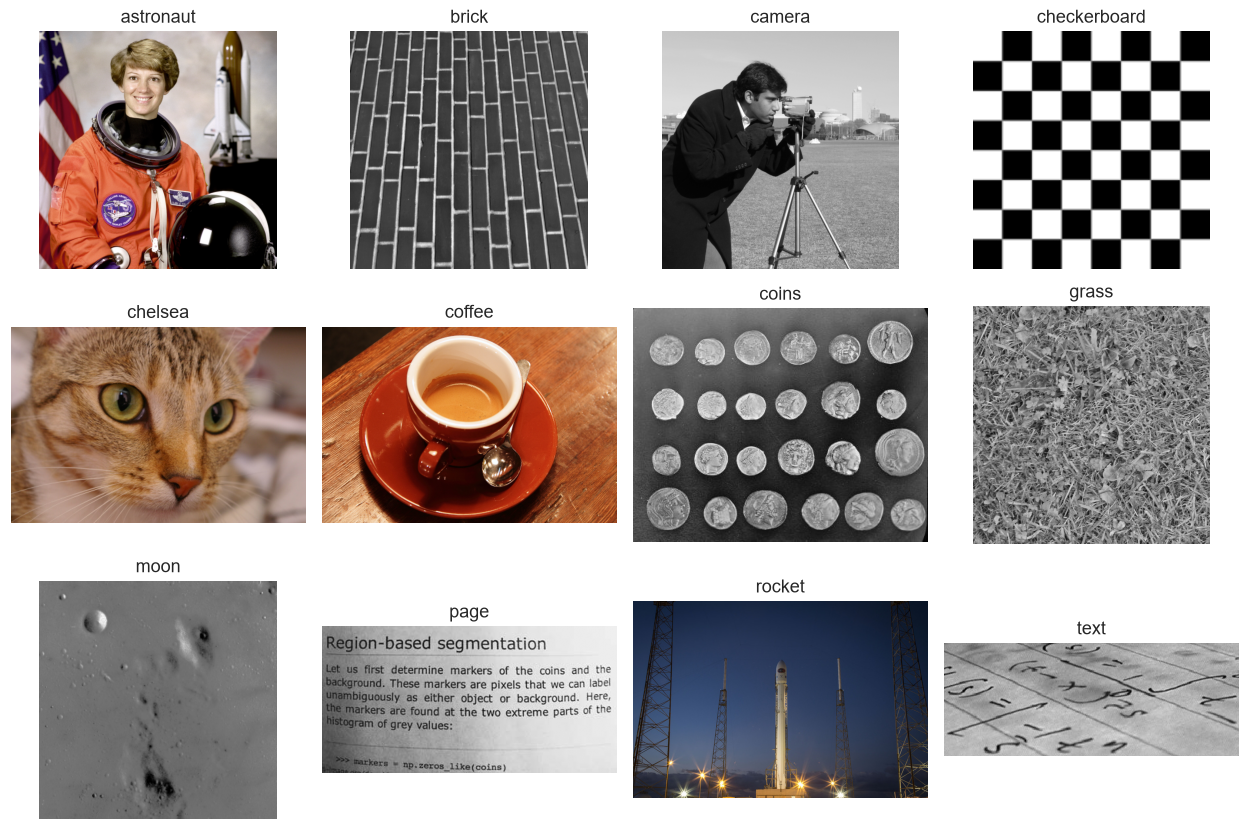

['astronaut.png', 'brick.png', 'camera.png', 'checkerboard.png', 'chelsea.png', 'coffee.png', 'coins.png', 'grass.png', 'moon.png', 'page.png', 'rocket.png', 'text.png']

In [3]:
DATA_DIR = RAW_DIR
SAMPLES_DIR = Path('data/samples')
OUTPUTS = {'preproc': Path('outputs/preproc'), 'features': Path('outputs/features'), 'metrics': Path('outputs/metrics')}
for folder in list(OUTPUTS.values()) + [SAMPLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
images = sorted(p for p in DATA_DIR.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'})
assert len(images) == 12
print('Imágenes encontradas:', len(images))
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for axis, path in zip(axes.flat, images):
    sample = skio.imread(path)
    axis.imshow(sample, cmap='gray' if sample.ndim == 2 else None)
    axis.set_title(path.stem)
    axis.axis('off')
plt.tight_layout(); plt.show()
[p.name for p in images]

## Parte A — Representación e inspección inicial
### A.1 Matriz y formato
OpenCV carga en BGR; Matplotlib muestra RGB. La conversión se hace explícitamente. Las fuentes en gris se leen con tres canales iguales cuando se usa `IMREAD_COLOR`; eso no significa que tuvieran color originalmente.

In [4]:
def read_image_bgr(path: Path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'No se pudo leer: {path}')
    return image

img_path = DATA_DIR / 'astronaut.png'
img_bgr = read_image_bgr(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
height, width = img_gray.shape
channels, dtype = img_rgb.shape[2], img_bgr.dtype
min_val, max_val = int(img_gray.min()), int(img_gray.max())
mean_gray = float(img_gray.mean())
percentiles = np.percentile(img_gray, [5, 50, 95])
channel_means = pd.Series(img_rgb.mean(axis=(0, 1)), index=['R', 'G', 'B'])
print('Imagen:', img_path.name)
print('H, W, C:', height, width, channels)
print('dtype:', dtype, '| rango:', (min_val, max_val), '| media gris:', round(mean_gray, 2))
print('Percentiles 5/50/95:', percentiles)
print('Medias de canales:', channel_means.round(2).to_dict())
assert img_gray.dtype == np.uint8 and img_rgb.shape == (*img_gray.shape, 3)

Imagen: astronaut.png
H, W, C: 512 512 3
dtype: uint8 | rango: (0, 255) | media gris: 115.41
Percentiles 5/50/95: [  0. 129. 217.]
Medias de canales: {'R': 141.56, 'G': 105.76, 'B': 96.48}


### A.2 Histogramas (diagnóstico)

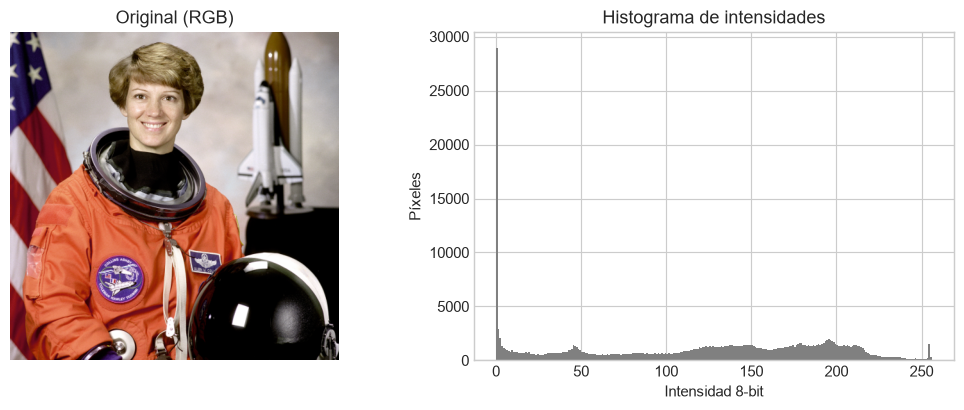

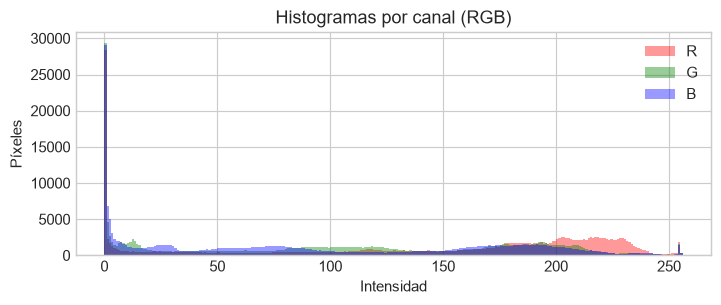

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_rgb); axes[0].set_title('Original (RGB)'); axes[0].axis('off')
axes[1].hist(img_gray.ravel(), bins=256, range=(0, 256), color='gray')
axes[1].set(title='Histograma de intensidades', xlabel='Intensidad 8-bit', ylabel='Píxeles')
plt.tight_layout(); plt.show()
fig, axis = plt.subplots(figsize=(7, 3))
for i, name in enumerate(['R', 'G', 'B']):
    axis.hist(img_rgb[..., i].ravel(), bins=256, range=(0, 256), alpha=.4, label=name, color=name.lower())
axis.set(title='Histogramas por canal (RGB)', xlabel='Intensidad', ylabel='Píxeles')
axis.legend(); plt.tight_layout(); plt.show()

### Preguntas de reflexión — Parte A

1. El rango dinámico observado fue **0 a 255**, con percentiles 5 y 95 en 0 y 217. Se utiliza un intervalo amplio de intensidades; el rango mínimo–máximo por sí solo no describe cómo se distribuye el resto de los píxeles.
2. El histograma muestra **contraste global alto**: combina sombras y regiones claras, y el intervalo entre percentiles 5–95 es 217. No es un histograma estrecho alrededor de una única intensidad. Aun así, una región local puede tener poco contraste.
3. Domina el canal **R**, según su media (141.56). Eso refleja la composición cromática de esta escena y sus objetos; no demuestra por sí solo un error de balance de blancos ni la iluminación de todo el dataset.

## Parte B — Espacios de color y contraste
### B.1 Cambio de espacio
Con entrada `uint8`, OpenCV representa H en 0–179 y S/V en 0–255; en LAB codifica L* en 0–255 y desplaza a*/b* para almacenarlos sin signo. No se comparan numéricamente esos canales como si compartieran unidades físicas. El tono H es inestable donde la saturación es muy baja.

Para luminancia/contraste: V L


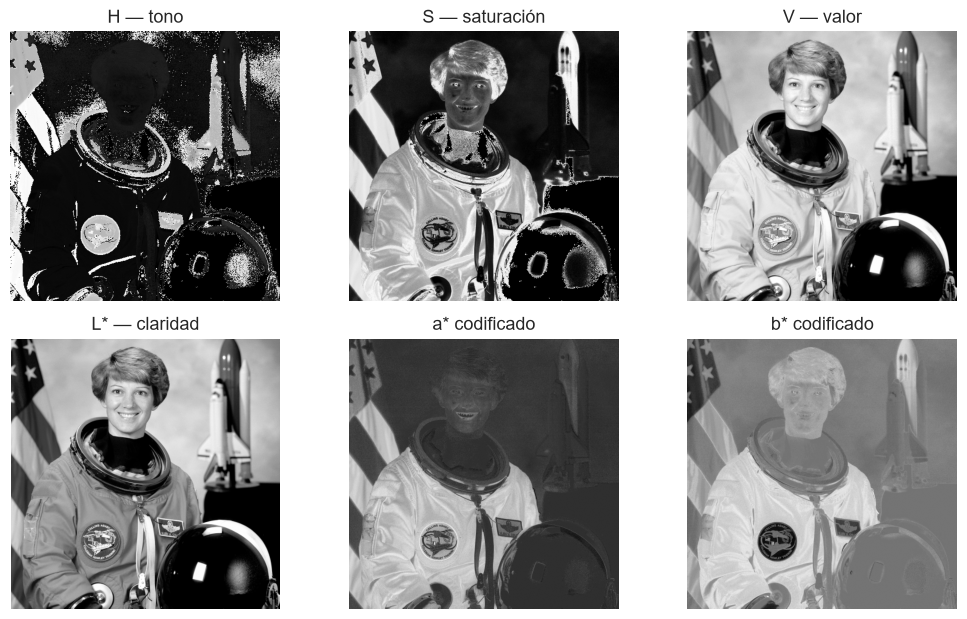

In [6]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
salient_hsv_channel, salient_lab_channel = 'V', 'L'
print('Para luminancia/contraste:', salient_hsv_channel, salient_lab_channel)
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for axis, image, label in zip(axes.flat, [img_hsv[..., 0], img_hsv[..., 1], img_hsv[..., 2], img_lab[..., 0], img_lab[..., 1], img_lab[..., 2]], ['H — tono', 'S — saturación', 'V — valor', 'L* — claridad', 'a* codificado', 'b* codificado']):
    axis.imshow(image, cmap='gray'); axis.set_title(label); axis.axis('off')
plt.tight_layout(); plt.show()

### B.2 Contraste: Global vs Adaptativo (CLAHE)
Se ecualiza el gris globalmente y se aplica CLAHE solo a L* para mantener los canales cromáticos. El límite de contraste reduce la amplificación de histogramas locales, pero no garantiza ausencia de ruido ni conservación exacta del color después de convertir y recortar al rango RGB.

STD contraste — original/global/CLAHE: [75.12 80.25 75.87]


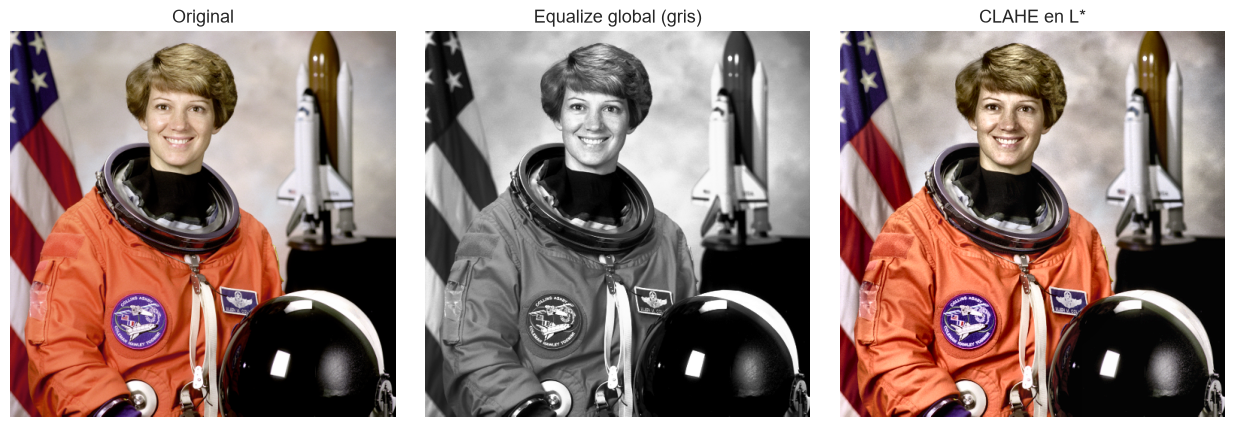

In [7]:
CLAHE_PARAMS = {'clipLimit': 2.0, 'tileGridSize': (8, 8)}
eq_gray = cv2.equalizeHist(img_gray)
L, A_lab, B_lab = cv2.split(img_lab)
clahe = cv2.createCLAHE(**CLAHE_PARAMS)
L_clahe = clahe.apply(L)
rgb_clahe = cv2.cvtColor(cv2.merge([L_clahe, A_lab, B_lab]), cv2.COLOR_LAB2RGB)
clahe_gray = cv2.cvtColor(rgb_clahe, cv2.COLOR_RGB2GRAY)

def contrast_std(x):
    return float(np.std(x.astype(np.float32)))

std_before, std_eq, std_clahe = map(contrast_std, [img_gray, eq_gray, clahe_gray])
print('STD contraste — original/global/CLAHE:', np.round([std_before, std_eq, std_clahe], 2))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, image, label in zip(axes, [img_rgb, eq_gray, rgb_clahe], ['Original', 'Equalize global (gris)', 'CLAHE en L*']):
    axis.imshow(image, cmap='gray' if image.ndim == 2 else None); axis.set_title(label); axis.axis('off')
plt.tight_layout(); plt.show()
for name, image in [('original', img_gray), ('global', eq_gray), ('claheL', clahe_gray)]:
    cv2.imwrite(str(OUTPUTS['preproc'] / f'astronaut_{name}.png'), image)

### Preguntas de reflexión — Parte B

1. Para este objetivo, **V en HSV y L* en LAB** son informativos porque separan brillo/claridad del color. Se eligió L* para ajustar contraste; para segmentar un objeto por tono usaría H y exigiría suficiente saturación, no H como regla universal.
2. CLAHE mejora la diferenciación local y limita picos del histograma por región. No se puede concluir que mejore siempre más que la ecualización global en zonas homogéneas: también puede amplificar pequeñas fluctuaciones. En esta imagen, que ya tiene contraste, hay que mirar detalle y ruido; el barrido extra lo evalúa con ruido controlado.
3. La STD cambia de **75.12** a **80.25** con global y a **75.87** con CLAHE. Esa cifra mide dispersión global, no calidad perceptual ni contraste de cada zona. CLAHE puede mejorar regiones locales sin superar a la global en STD.

## Parte C — Suavizado y bordes
### C.1 Suavizado
Se fija Gaussian 5×5, sigma 1,2, y bilateral d=9, sigmaColor=75, sigmaSpace=75. El bilateral pondera distancia e intensidad: puede evitar mezclar ambos lados de un borde fuerte. Estas parametrizaciones no representan necesariamente el mismo nivel de reducción de ruido.

In [8]:
GAUSS_PARAMS = {'ksize': (5, 5), 'sigmaX': 1.2}
BILAT_PARAMS = {'d': 9, 'sigmaColor': 75, 'sigmaSpace': 75}
gaussian = cv2.GaussianBlur(img_gray, **GAUSS_PARAMS)
bilateral = cv2.bilateralFilter(img_gray, **BILAT_PARAMS)

def gradient_magnitude(x):
    gx = cv2.Sobel(x, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(x, cv2.CV_32F, 0, 1, ksize=3)
    return np.hypot(gx, gy)

def grad_variance(x):
    return float(np.var(gradient_magnitude(x)))

gv_before, gv_gauss, gv_bilat = map(grad_variance, [img_gray, gaussian, bilateral])
print('Var(grad) — original/gaussian/bilateral:', np.round([gv_before, gv_gauss, gv_bilat], 2))

Var(grad) — original/gaussian/bilateral: [10788.16  4926.56  5488.11]


### C.2 Bordes
Se usan los mismos umbrales Canny 50/150 en todas las variantes para poder compararlas. El ratio de bordes mide proporción de píxeles detectados: incluye estructura, textura y posible ruido, por lo que no alcanza para separar esas causas.

Edges ratio — original/gaussian/bilateral: [0.1022 0.065  0.049 ]
Cobertura de bordes fuertes originales (tolerancia 1 píxel): {'gaussian': 0.8205, 'bilateral': 0.6431}


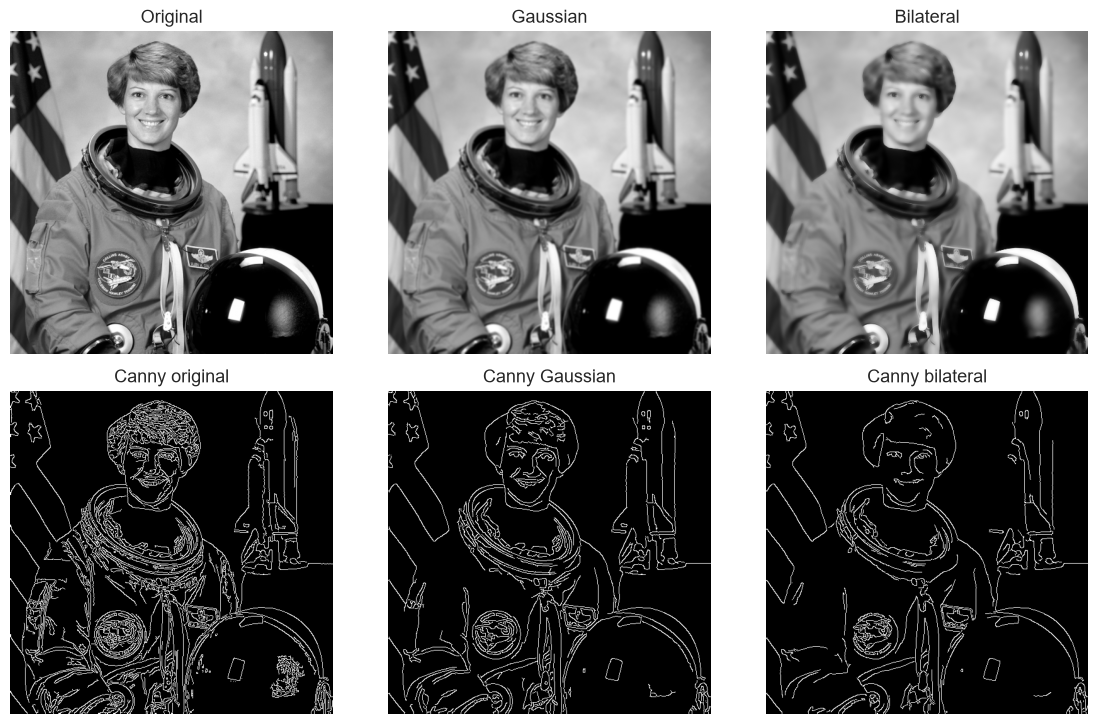

In [9]:
CANNY_THRESHOLDS = (50, 150)
edges_before = cv2.Canny(img_gray, *CANNY_THRESHOLDS)
edges_gauss = cv2.Canny(gaussian, *CANNY_THRESHOLDS)
edges_bilat = cv2.Canny(bilateral, *CANNY_THRESHOLDS)

def edge_ratio(x):
    return float((x > 0).mean())

er_before, er_gauss, er_bilat = map(edge_ratio, [edges_before, edges_gauss, edges_bilat])
strong_edges = cv2.Canny(img_gray, 100, 200) > 0
retention = {name: float((cv2.dilate(edges, np.ones((3, 3), np.uint8))[strong_edges] > 0).mean()) for name, edges in [('gaussian', edges_gauss), ('bilateral', edges_bilat)]}
print('Edges ratio — original/gaussian/bilateral:', np.round([er_before, er_gauss, er_bilat], 4))
print('Cobertura de bordes fuertes originales (tolerancia 1 píxel):', {k: round(v, 4) for k, v in retention.items()})
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for axis, image, label in zip(axes.flat, [img_gray, gaussian, bilateral, edges_before, edges_gauss, edges_bilat], ['Original', 'Gaussian', 'Bilateral', 'Canny original', 'Canny Gaussian', 'Canny bilateral']):
    axis.imshow(image, cmap='gray'); axis.set_title(label); axis.axis('off')
plt.tight_layout(); plt.show()

### Preguntas de reflexión — Parte C

1. El bilateral está diseñado para conservar discontinuidades fuertes mientras suaviza regiones parecidas. Con estos parámetros, el mayor valor de cobertura de bordes fuertes lo obtuvo **gaussian**: Gaussian 82.0%, bilateral 64.3%. Se compara contra los bordes de la entrada, no contra ground truth; no se declara un ganador universal sin igualar el nivel de denoising.
2. El ratio pasa de 10.22% a 6.50% con Gaussian y a 4.90% con bilateral. El descenso indica eliminación de respuestas finas, que pueden ser ruido o detalle real. Sin una referencia limpia no se pueden llamar “falsos” a todos los bordes eliminados; el extra 1 agrega ruido conocido para construir un proxy controlado.
3. Para escenas nocturnas probaría Canny **(25, 75)** porque gradientes más débiles pueden quedar bajo 50/150. También aplicaría reducción de ruido y evaluaría falsos positivos: bajar umbrales no recupera información inexistente y puede detectar más ruido.

## Parte D — Puntos de interés y descriptores
### D.1 Detección en variantes
ORB produce descriptores binarios; se fija `nfeatures=1000`, `scaleFactor=1.2`, `nlevels=8`. Se incorpora bilateral además de las tres variantes de la guía. Cantidad y densidad de puntos no son sinónimos de calidad; alcanzar el límite de 1000 también oculta diferencias entre imágenes.

  variant  num_keypoints  kp_per_megapixel  descriptor_size_bytes
     orig           1000            3814.7                     32
    gauss           1000            3814.7                     32
bilateral           1000            3814.7                     32
   claheL           1000            3814.7                     32


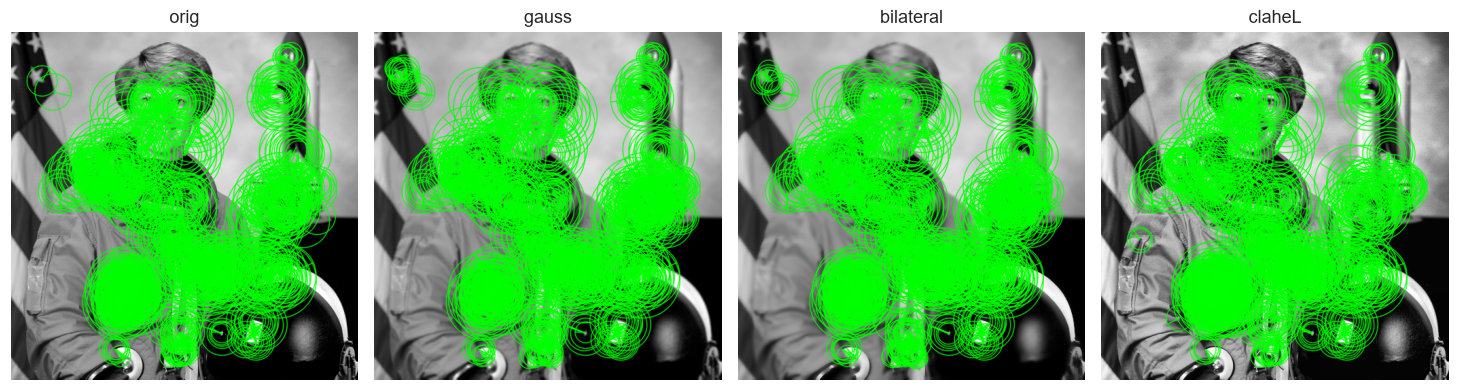

,variant,num_keypoints,kp_per_megapixel,descriptor_size_bytes
0,orig,1000,3814.697266,32
1,gauss,1000,3814.697266,32
2,bilateral,1000,3814.697266,32
3,claheL,1000,3814.697266,32


In [10]:
ORB_PARAMS = {'nfeatures': 1000, 'scaleFactor': 1.2, 'nlevels': 8}
variants = {'orig': img_gray, 'gauss': gaussian, 'bilateral': bilateral, 'claheL': clahe_gray}
orb = cv2.ORB_create(**ORB_PARAMS)
kp_stats, overlay_examples, detected = [], [], {}
for name, image in variants.items():
    keypoints, descriptors = orb.detectAndCompute(image, None)
    detected[name] = (keypoints, descriptors)
    kp_stats.append({'variant': name, 'num_keypoints': len(keypoints), 'kp_per_megapixel': len(keypoints)/image.size*1e6,
        'descriptor_size_bytes': 0 if descriptors is None else descriptors.shape[1]})
    overlay = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS, color=(0, 255, 0))
    overlay_examples.append((name, cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)))
    cv2.imwrite(str(OUTPUTS['features'] / f'astronaut_{name}_orb.png'), overlay)
kp_table = pd.DataFrame(kp_stats)
print(kp_table.round(2).to_string(index=False))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, (name, overlay) in zip(axes, overlay_examples):
    axis.imshow(overlay); axis.set_title(name); axis.axis('off')
plt.tight_layout(); plt.show()
kp_table

### D.2 Matching y repetibilidad (A vs A’)
Se mantiene el matching ORB con Hamming y cross-check. Un match mutuo puede ser incorrecto: se valida que sus posiciones coincidan a menos de 3 píxeles porque CLAHE no cambia la geometría. `matches_ratio` es matches / mínimo número de keypoints; el ratio validado usa solamente matches consistentes con esa geometría. Ninguno reemplaza una medición independiente de repetibilidad del detector.

Keypoints original/CLAHE: 1000 1000
Matches: 617 | ratio: 0.617
Matches geométricamente válidos: 572 | ratio válido: 0.572 | precisión geométrica: 0.9271


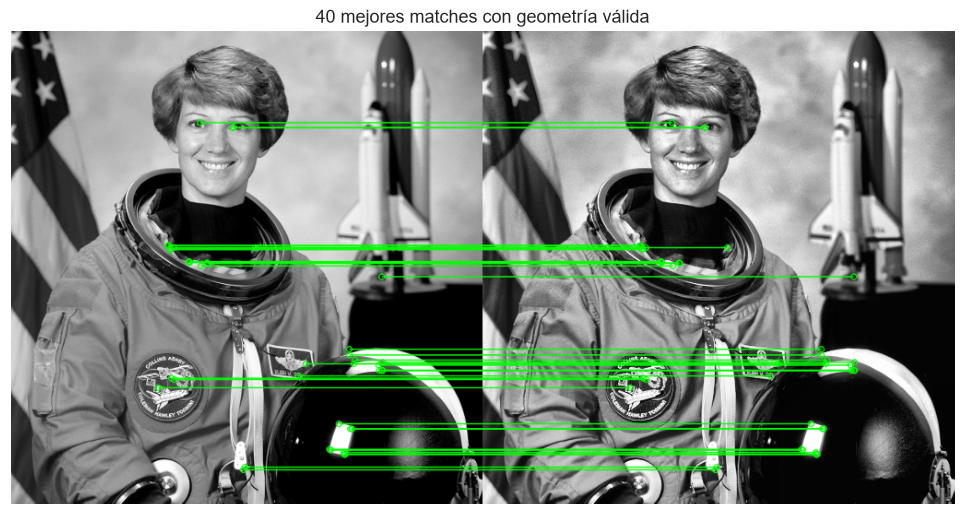

In [11]:
kp1, des1 = detected['orig']
kp2, des2 = detected['claheL']
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda m: m.distance) if des1 is not None and des2 is not None else []
matches_ratio = len(matches)/max(1, min(len(kp1), len(kp2)))
geometric_errors = np.array([np.linalg.norm(np.array(kp1[m.queryIdx].pt) - kp2[m.trainIdx].pt) for m in matches])
valid_matches = [match for match, error in zip(matches, geometric_errors) if error <= 3.0]
valid_matches_ratio = len(valid_matches)/max(1, min(len(kp1), len(kp2)))
match_precision = len(valid_matches)/max(1, len(matches))
print('Keypoints original/CLAHE:', len(kp1), len(kp2))
print('Matches:', len(matches), '| ratio:', round(matches_ratio, 4))
print('Matches geométricamente válidos:', len(valid_matches), '| ratio válido:', round(valid_matches_ratio, 4), '| precisión geométrica:', round(match_precision, 4))
match_image = cv2.drawMatches(img_gray, kp1, clahe_gray, kp2, valid_matches[:40], None, flags=2, matchColor=(0, 255, 0))
cv2.imwrite(str(OUTPUTS['features'] / 'astronaut_orig_clahe_matches.png'), match_image)
plt.figure(figsize=(12, 5)); plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB)); plt.title('40 mejores matches con geometría válida'); plt.axis('off'); plt.tight_layout(); plt.show()

### Pipeline por lote y métricas reproducibles
Se conservan parámetros, baseline e indicadores por imagen/variante. En caso de no obtener descriptores, los ratios se devuelven como cero y la imagen no interrumpe el procesamiento.

In [12]:
def make_variants(bgr, clip_limit=2.0, tiles=(8, 8)):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    local = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tiles).apply(lab[..., 0])
    lab[..., 0] = local
    rgb_local = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return {'orig': gray, 'gauss': cv2.GaussianBlur(gray, **GAUSS_PARAMS),
        'bilateral': cv2.bilateralFilter(gray, **BILAT_PARAMS),
        'claheL': cv2.cvtColor(rgb_local, cv2.COLOR_RGB2GRAY)}

def match_report(kpa, desa, kpb, desb, norm=cv2.NORM_HAMMING, matrix=None):
    if desa is None or desb is None or not len(kpa) or not len(kpb):
        return {'matches': 0, 'matches_ratio': 0., 'valid_matches': 0, 'valid_ratio': 0., 'geometric_precision': 0.}
    pairs = cv2.BFMatcher(norm, crossCheck=True).match(desa, desb)
    pa = np.array([kpa[m.queryIdx].pt for m in pairs], dtype=np.float32).reshape(-1, 2)
    pb = np.array([kpb[m.trainIdx].pt for m in pairs], dtype=np.float32).reshape(-1, 2)
    if matrix is not None and len(pa):
        pa = cv2.transform(pa[None], matrix)[0]
    valid = int((np.linalg.norm(pa-pb, axis=1) <= 3.0).sum())
    denominator = max(1, min(len(kpa), len(kpb)))
    return {'matches': len(pairs), 'matches_ratio': len(pairs)/denominator,
        'valid_matches': valid, 'valid_ratio': valid/denominator, 'geometric_precision': valid/max(1, len(pairs))}

loaded = {path.stem: read_image_bgr(path) for path in images}
batch_rows = []
for name, bgr in loaded.items():
    prepared = make_variants(bgr)
    base_kp, base_des = orb.detectAndCompute(prepared['orig'], None)
    for variant, image in prepared.items():
        keypoints, descriptors = orb.detectAndCompute(image, None)
        row = {'image': name, 'variant': variant, 'height': image.shape[0], 'width': image.shape[1],
            'contrast_std': contrast_std(image), 'edges_ratio': edge_ratio(cv2.Canny(image, *CANNY_THRESHOLDS)),
            'grad_variance': grad_variance(image), 'num_keypoints': len(keypoints), 'kp_per_megapixel': len(keypoints)/image.size*1e6}
        row.update(match_report(base_kp, base_des, keypoints, descriptors))
        batch_rows.append(row)
        cv2.imwrite(str(OUTPUTS['preproc'] / f'{name}_{variant}.png'), image)
batch_metrics = pd.DataFrame(batch_rows)
batch_metrics.to_csv(OUTPUTS['metrics'] / 'metricas_por_imagen.csv', index=False)
parameters = {'seed': SEED, 'clahe': CLAHE_PARAMS, 'gaussian': GAUSS_PARAMS,
    'bilateral': BILAT_PARAMS, 'canny': CANNY_THRESHOLDS, 'orb': ORB_PARAMS, 'geometric_tolerance_px': 3.0}
(OUTPUTS['metrics'] / 'parametros.json').write_text(json.dumps(parameters, indent=2), encoding='utf-8')
assert len(batch_metrics) == 48
assert batch_metrics[['matches_ratio', 'valid_ratio', 'geometric_precision', 'edges_ratio']].ge(0).all().all()
assert batch_metrics[['matches_ratio', 'valid_ratio', 'geometric_precision', 'edges_ratio']].le(1).all().all()
print(batch_metrics.groupby('variant')[['num_keypoints', 'contrast_std', 'edges_ratio', 'valid_ratio']].mean().round(3).to_string())
batch_metrics.head(8).round(3)

           num_keypoints  contrast_std  edges_ratio  valid_ratio
variant                                                         
bilateral        581.167        46.069        0.050        0.633
claheL           897.083        56.573        0.165        0.437
gauss            679.417        46.519        0.070        0.638
orig             826.917        50.177        0.116        0.946


,image,variant,height,width,contrast_std,edges_ratio,grad_variance,num_keypoints,kp_per_megapixel,matches,matches_ratio,valid_matches,valid_ratio,geometric_precision
0,astronaut,orig,512,512,75.123,0.102,10788.159,1000,3814.697,1000,1.000,1000,1.000,1.000
1,astronaut,gauss,512,512,73.323,0.065,4926.560,1000,3814.697,664,0.664,644,0.644,0.970
2,astronaut,bilateral,512,512,72.943,0.049,5488.110,1000,3814.697,682,0.682,659,0.659,0.966
3,astronaut,claheL,512,512,75.868,0.130,13870.871,1000,3814.697,617,0.617,572,0.572,0.927
4,brick,orig,512,512,26.052,0.075,6073.593,1000,3814.697,1000,1.000,1000,1.000,1.000
5,brick,gauss,512,512,23.006,0.071,3215.457,953,3635.406,655,0.687,581,0.610,0.887
6,brick,bilateral,512,512,19.984,0.063,1664.986,598,2281.189,380,0.635,269,0.450,0.708
7,brick,claheL,512,512,37.769,0.086,11999.852,1000,3814.697,494,0.494,323,0.323,0.654


### Preguntas de reflexión — Parte D

1. La mayor densidad en el ejemplo corresponde a **orig, gauss, bilateral, claheL**, con 1000 puntos. El tamaño de las variantes es idéntico, por lo que el orden de densidad coincide con el conteo. CLAHE puede hacer visibles contrastes pequeños; el blur puede eliminar esquinas finas. El límite de 1000 y el contenido de la escena condicionan la comparación.
2. Original vs CLAHE produce **61.7%** de matches respecto del mínimo de puntos, pero solo **57.2%** son válidos geométricamente, con precisión 92.7%. Sobre el lote, el ratio validado medio es 43.7% para CLAHE y 63.8% para Gaussian. Se observan cambios al alterar intensidades y detecciones; el número de matches mutuos aislado no prueba repetibilidad.
3. Para un presupuesto menor probaría **nfeatures=750, scaleFactor=1.2**, conservando 8 niveles. Reduciría el máximo de descriptores y el matching, pero hay que medir cuántas correspondencias válidas se pierden. Es una propuesta para validar, no una configuración declarada óptima sin experimento.

## Preguntas de reflexión finales

1. La transformación útil depende de la imagen: CLAHE en L* es razonable en escenas de bajo contraste, mientras conservaría el baseline si ya tiene buen contraste y puntos estables. En `moon`, la STD original es 13.33 y con CLAHE 17.97; los keypoints pasan de 645 a 942. Eso no demuestra mejora semántica: también se inspecciona ruido y geometría.
2. Elegí **L*** para contraste preservando a*/b*; usaría **H** para segmentación cromática si hay saturación suficiente. El canal más informativo depende de la tarea, no se elige una sola vez para toda visión por computadora.
3. El trade-off es quitar ruido sin perder esquinas y contornos útiles. Seleccionaría el menor suavizado que reduzca falsas respuestas y conserve suficientes matches válidos; no maximizaría automáticamente el número de bordes ni la STD.
4. Como punto de partida: alerta si **num_keypoints < 100**, **edges_ratio fuera de [0.02, 0.15]**, **STD < 20**, precisión geométrica < 0.70 o caída de STD por debajo del 80% del baseline de la misma imagen. Son umbrales de diagnóstico, no criterios universales de descarte: texturas uniformes, documentos y tableros requieren perfiles distintos. El dashboard aplica estas reglas y registra razones y parámetros.

## Tareas extra (opcional)
### 1) Curva sensibilidad–ruido
Se agrega ruido gaussiano de sigma=10/255 a cada imagen, con semilla fija. Se barren clipLimit {1.5, 2, 4}, tiles {4×4, 8×8} y suavizado {ninguno, Gaussian, bilateral}: 18 configuraciones por imagen. El proxy cuenta bordes nuevos en regiones de bajo gradiente de la imagen limpia y alejados de sus bordes originales. No se considera ground truth: la textura real y la interpolación pueden afectar el indicador.

Configuraciones: 18 | evaluaciones: 216


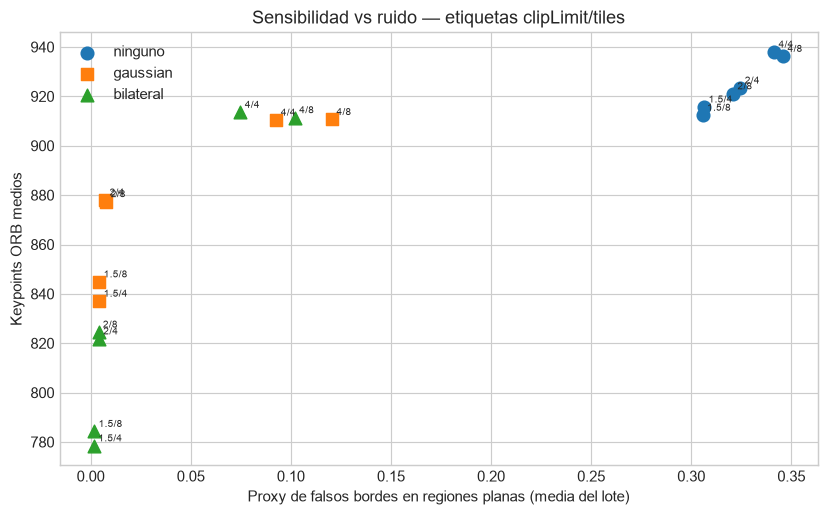

,clip,tile,smoothing,num_keypoints,false_edge_proxy,contrast_std
0,1.5,4,bilateral,778.5000,0.0016,49.7977
1,1.5,4,gaussian,837.0833,0.0043,50.0472
2,1.5,4,ninguno,915.7500,0.3065,58.3038
3,1.5,8,bilateral,784.3333,0.0018,47.8111
4,1.5,8,gaussian,844.9167,0.0043,48.0432
5,1.5,8,ninguno,912.4167,0.3057,56.8084
6,2.0,4,bilateral,821.8333,0.0041,51.4384
7,2.0,4,gaussian,878.0833,0.0073,51.3679
8,2.0,4,ninguno,923.4167,0.3246,60.8509
9,2.0,8,bilateral,824.5833,0.0039,48.7719


In [13]:
sensitivity_rows = []
rng = np.random.default_rng(SEED)
for name, bgr in loaded.items():
    clean = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    noisy = np.clip(clean.astype(float) + rng.normal(0, 10, clean.shape), 0, 255).astype(np.uint8)
    flat = gradient_magnitude(clean) <= np.quantile(gradient_magnitude(clean), .25)
    near_structure = cv2.dilate(cv2.Canny(clean, *CANNY_THRESHOLDS), np.ones((5, 5), np.uint8)) > 0
    evaluation_mask = flat & ~near_structure
    for clip in [1.5, 2., 4.]:
        for tile in [4, 8]:
            enhanced = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(noisy)
            candidates = {'ninguno': enhanced, 'gaussian': cv2.GaussianBlur(enhanced, **GAUSS_PARAMS), 'bilateral': cv2.bilateralFilter(enhanced, **BILAT_PARAMS)}
            for smoothing, image in candidates.items():
                keypoints = orb.detect(image, None)
                edges = cv2.Canny(image, *CANNY_THRESHOLDS) > 0
                sensitivity_rows.append({'image': name, 'clip': clip, 'tile': tile, 'smoothing': smoothing,
                    'num_keypoints': len(keypoints), 'false_edge_proxy': float((edges & evaluation_mask).sum()/max(1, evaluation_mask.sum())),
                    'contrast_std': contrast_std(image)})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUTPUTS['metrics'] / 'sensibilidad_ruido.csv', index=False)
sensitivity_summary = sensitivity.groupby(['clip', 'tile', 'smoothing'], as_index=False).agg(num_keypoints=('num_keypoints', 'mean'), false_edge_proxy=('false_edge_proxy', 'mean'), contrast_std=('contrast_std', 'mean'))
fig, axis = plt.subplots(figsize=(8, 5))
for smoothing, marker in [('ninguno', 'o'), ('gaussian', 's'), ('bilateral', '^')]:
    subset = sensitivity_summary.loc[sensitivity_summary.smoothing == smoothing]
    axis.scatter(subset.false_edge_proxy, subset.num_keypoints, label=smoothing, marker=marker, s=75)
    for row in subset.itertuples():
        axis.annotate(f'{row.clip:g}/{row.tile}', (row.false_edge_proxy, row.num_keypoints), xytext=(3, 3), textcoords='offset points', fontsize=7)
axis.set(xlabel='Proxy de falsos bordes en regiones planas (media del lote)', ylabel='Keypoints ORB medios', title='Sensibilidad vs ruido — etiquetas clipLimit/tiles')
axis.legend(); plt.tight_layout(); plt.show()
print('Configuraciones:', len(sensitivity_summary), '| evaluaciones:', len(sensitivity))
sensitivity_summary.round(4)

**Resultado:** la configuración con menor proxy medio es {'clip': 1.5, 'tile': 4, 'smoothing': 'bilateral'}, con proxy 0.0016. El mayor conteo medio de puntos es 938.0. Más puntos no significan más señal: CLAHE puede amplificar ruido y crear esquinas espurias. Se elegiría un compromiso según el mínimo de correspondencias útiles requerido. Aquí se ecualiza el gris para aislar contraste/ruido; en el pipeline color de la parte B se trabaja sobre L*.

### 2) Benchmark mini-matching: SIFT vs ORB
Se compara ORB binario (Hamming) con SIFT flotante (L2), ambos con presupuesto aproximado de 1000 puntos. A cada imagen se le aplica una rotación conocida de 10°, escala 0,95 y cambio de brillo `0.85·I+10`. Se evalúa el error del match contra esa transformación, con tolerancia de 3 píxeles. Se usan tres repeticiones y la mediana del tiempo combinado de detección, descripción y matching; la carga de disco queda fuera.

La transformación puede recortar bordes y reduce el área común. Los ratios usan el mínimo de puntos detectados en las imágenes completas, por lo que no son una repetibilidad corregida por visibilidad. Los tiempos son relativos a este equipo, versiones y resoluciones, no un ranking universal.

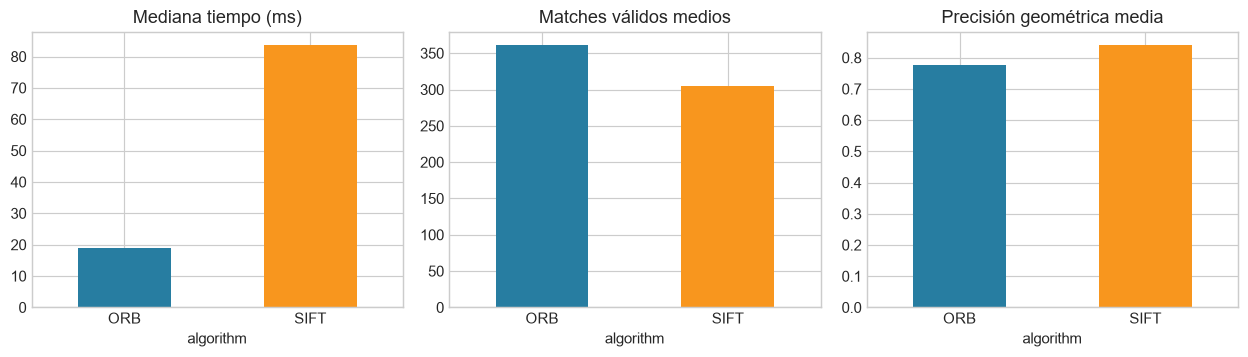

,time_median_ms,valid_mean,precision_mean,valid_ratio_mean,descriptor_bytes
algorithm,,,,,
ORB,19.069,361.50,0.778,0.456,32.0
SIFT,83.726,304.75,0.841,0.509,512.0


In [14]:
benchmark_rows = []
for name, bgr in loaded.items():
    original = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    h, w = original.shape
    matrix = cv2.getRotationMatrix2D((w/2, h/2), 10, .95)
    changed = cv2.warpAffine(original, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT)
    changed = cv2.convertScaleAbs(changed, alpha=.85, beta=10)
    for algorithm in ['ORB', 'SIFT']:
        detector = cv2.ORB_create(**ORB_PARAMS) if algorithm == 'ORB' else cv2.SIFT_create(nfeatures=1000)
        norm = cv2.NORM_HAMMING if algorithm == 'ORB' else cv2.NORM_L2
        # Calentamiento fuera del tiempo medido.
        detector.detectAndCompute(original, None)
        elapsed = []
        for repeat in range(3):
            cv2.setRNGSeed(SEED)
            start = time.perf_counter()
            kpa, desa = detector.detectAndCompute(original, None)
            kpb, desb = detector.detectAndCompute(changed, None)
            report = match_report(kpa, desa, kpb, desb, norm, matrix)
            elapsed.append((time.perf_counter()-start)*1000)
        benchmark_rows.append({'image': name, 'algorithm': algorithm, 'milliseconds': float(np.median(elapsed)),
            'keypoints_a': len(kpa), 'keypoints_b': len(kpb), 'descriptor_bytes_per_point': 0 if desa is None else desa.shape[1]*desa.dtype.itemsize, **report})
benchmark = pd.DataFrame(benchmark_rows)
benchmark.to_csv(OUTPUTS['metrics'] / 'benchmark_orb_sift.csv', index=False)
benchmark_summary = benchmark.groupby('algorithm').agg(time_median_ms=('milliseconds', 'median'), valid_mean=('valid_matches', 'mean'), precision_mean=('geometric_precision', 'mean'), valid_ratio_mean=('valid_ratio', 'mean'), descriptor_bytes=('descriptor_bytes_per_point', 'median'))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, metric, title in zip(axes, ['time_median_ms', 'valid_mean', 'precision_mean'], ['Mediana tiempo (ms)', 'Matches válidos medios', 'Precisión geométrica media']):
    benchmark_summary[metric].plot.bar(ax=axis, color=['#277da1', '#f8961e'])
    axis.set_title(title); axis.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
benchmark_summary.round(3)

**Resultado:** ORB tarda una mediana de 19.07 ms y SIFT 83.73 ms; el cociente SIFT/ORB es 4.39. Los matches geométricamente válidos medios son 361.5 y 304.8; la precisión media es 77.8% y 84.1%, respectivamente. ORB usa 32 bytes por descriptor, SIFT 512. La selección depende del presupuesto, memoria y correspondencias válidas necesarias; texturas repetidas pueden producir matches ambiguos aun con muchos puntos.

### 3) Dashboard QA por lote
Se calculan conteo de puntos, contraste, porcentaje de bordes y matching validado por imagen/variante. Las alertas incluyen motivos concretos; se comparan con el baseline de la misma imagen, no solamente con una media de escenas heterogéneas. Se agregan dos controles de diagnóstico: imagen uniforme y blur fuerte. Los umbrales son propuestas ajustables y no un detector universal de imágenes malas.

Dashboard guardado en outputs/metrics/dashboard_qa.html
Controles:
       image  num_keypoints                                                                                                          alerts
   uniforme              0 pocos keypoints; ratio de bordes fuera de perfil; STD baja; matches poco consistentes; caída de STD vs baseline
blur_fuerte             30                                     pocos keypoints; ratio de bordes fuera de perfil; matches poco consistentes


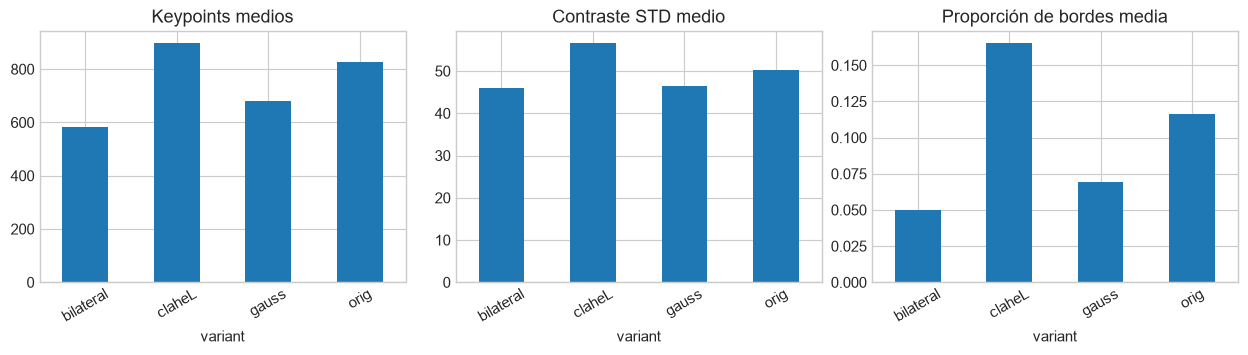

,images,keypoints_mean,contrast_mean,edges_mean,valid_ratio_mean,alerts
variant,,,,,,
bilateral,12,581.1667,46.0690,0.0499,0.6329,6
claheL,12,897.0833,56.5732,0.1652,0.4373,10
gauss,12,679.4167,46.5194,0.0695,0.6384,4
orig,12,826.9167,50.1766,0.1161,0.9461,2


In [15]:
qa_thresholds = {'min_keypoints': 100, 'min_edges': .02, 'max_edges': .15, 'min_std': 20,
    'min_geometric_precision': .70, 'min_relative_std': .80}

def qa_alerts(row):
    alerts = []
    if row.num_keypoints < qa_thresholds['min_keypoints']:
        alerts.append('pocos keypoints')
    if not qa_thresholds['min_edges'] <= row.edges_ratio <= qa_thresholds['max_edges']:
        alerts.append('ratio de bordes fuera de perfil')
    if row.contrast_std < qa_thresholds['min_std']:
        alerts.append('STD baja')
    if row.variant != 'orig' and row.geometric_precision < qa_thresholds['min_geometric_precision']:
        alerts.append('matches poco consistentes')
    if row.relative_std < qa_thresholds['min_relative_std']:
        alerts.append('caída de STD vs baseline')
    return '; '.join(alerts) or 'OK'

baseline = batch_metrics.loc[batch_metrics.variant == 'orig', ['image', 'contrast_std']].rename(columns={'contrast_std': 'baseline_std'})
qa = batch_metrics.merge(baseline, on='image', validate='many_to_one')
qa['relative_std'] = qa.contrast_std / qa.baseline_std.replace(0, np.nan)
qa['alerts'] = qa.apply(qa_alerts, axis=1)
qa.to_csv(OUTPUTS['metrics'] / 'qa_por_imagen.csv', index=False)
(OUTPUTS['metrics'] / 'umbrales_qa.json').write_text(json.dumps(qa_thresholds, indent=2), encoding='utf-8')
qa_summary = qa.groupby('variant').agg(images=('image', 'count'), keypoints_mean=('num_keypoints', 'mean'), contrast_mean=('contrast_std', 'mean'), edges_mean=('edges_ratio', 'mean'), valid_ratio_mean=('valid_ratio', 'mean'), alerts=('alerts', lambda s: int((s != 'OK').sum())))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, metric, title in zip(axes, ['keypoints_mean', 'contrast_mean', 'edges_mean'], ['Keypoints medios', 'Contraste STD medio', 'Proporción de bordes media']):
    qa_summary[metric].plot.bar(ax=axis)
    axis.set_title(title); axis.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

controls = {'uniforme': np.full_like(img_gray, 128), 'blur_fuerte': cv2.GaussianBlur(img_gray, (31, 31), 10)}
control_rows = []
for name, image in controls.items():
    keys, desc = orb.detectAndCompute(image, None)
    control_rows.append({'image': name, 'variant': 'control', 'num_keypoints': len(keys),
        'edges_ratio': edge_ratio(cv2.Canny(image, *CANNY_THRESHOLDS)), 'contrast_std': contrast_std(image),
        'geometric_precision': match_report(kp1, des1, keys, desc)['geometric_precision'],
        'relative_std': contrast_std(image)/std_before})
control_table = pd.DataFrame(control_rows)
control_table['alerts'] = control_table.apply(qa_alerts, axis=1)
assert control_table.loc[control_table.image == 'uniforme', 'num_keypoints'].iloc[0] == 0
assert control_table.loc[control_table.image == 'uniforme', 'alerts'].iloc[0] != 'OK'
control_table.to_csv(OUTPUTS['metrics'] / 'qa_controles.csv', index=False)
selected = ['image', 'variant', 'num_keypoints', 'contrast_std', 'edges_ratio', 'valid_ratio', 'geometric_precision', 'alerts']
dashboard = qa[selected].round(4).style.map(lambda x: 'background-color: #e7f5e7' if x == 'OK' else 'background-color: #ffe4d9', subset=['alerts'])
html = '<!doctype html><html lang="es"><meta charset="utf-8"><title>QA de imágenes</title><style>body{font:15px system-ui;margin:24px}table{border-collapse:collapse}td,th{padding:7px;border:1px solid #ddd}</style><h1>QA del lote de imágenes</h1><p>12 imágenes · 4 variantes · ORB · umbrales heurísticos ajustables. Fuentes y parámetros adjuntos.</p>' + qa_summary.round(4).to_html() + dashboard.to_html() + '<h2>Controles de diagnóstico</h2>' + control_table.round(4).to_html(index=False) + '</html>'
(OUTPUTS['metrics'] / 'dashboard_qa.html').write_text(html, encoding='utf-8')
print('Dashboard guardado en outputs/metrics/dashboard_qa.html')
print('Controles:\n', control_table[['image', 'num_keypoints', 'alerts']].to_string(index=False))
qa_summary.round(4)

**Resultado QA:** 22 de las 48 combinaciones imagen/variante disparan al menos una regla. Se interpretan según el contenido: `checkerboard` puede tener correspondencias ambiguas por repetición, y una imagen uniforme no debería generar esquinas. El control uniforme fue detectado sin descriptores y el pipeline continuó. Los controles no se mezclan con las doce imágenes originales al resumir el lote.

## Conclusión
El preprocesamiento modifica tanto la apariencia como las features que llegan a una tarea posterior. No conviene aplicar CLAHE o blur por costumbre: se compara el baseline, se registra cada parámetro y se revisa qué detalle útil se pierde o qué ruido se amplifica. Histogramas, STD y cantidad de puntos son diagnósticos parciales; la consistencia geométrica ayuda a evaluar si las correspondencias son útiles.

Se conservaron las imágenes originales, variantes PNG, overlays, parámetros y métricas CSV. El dashboard HTML es una vista del mismo lote, sin depender de servicios externos.